In [1]:

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np


In [2]:

california_data = fetch_california_housing(as_frame=True)
df = california_data.frame

print("Данные успешно загружены!")
print(f"Размер датасета: {df.shape}")


Данные успешно загружены!
Размер датасета: (20640, 9)


In [3]:

df.head()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [5]:

df.describe()


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


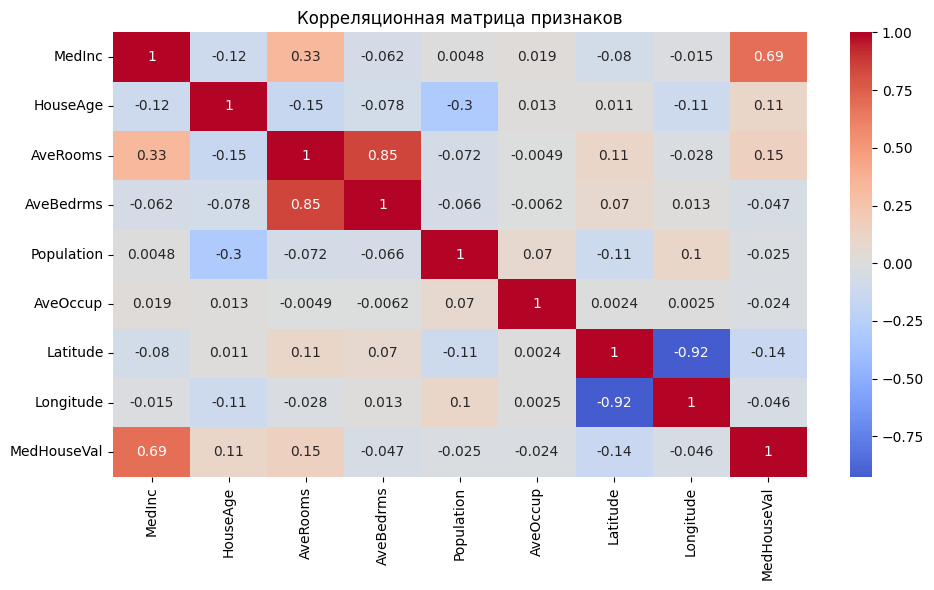

In [6]:

plt.figure(figsize=(10, 6))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', center=0)
plt.title("Корреляционная матрица признаков")
plt.tight_layout()
plt.show()


На основе корреляционной матрицы можно сделать следующие выводы:

- MedInc (медианный доход) имеет самую сильную положительную корреляцию с целевой переменной MedHouseVal.
- Latitude и Longitude также связаны со стоимостью жилья, что отражает географические различия.
- AveRooms и AveBedrms имеют слабую положительную корреляцию с ценой.
- Population и AveOccup показывают очень слабую корреляцию с целевой переменной.
- AveRooms и AveBedrms сильно коррелируют между собой, что может вызвать мультиколлинеарность в линейных моделях.

In [7]:

y = df['MedHouseVal']
x = df.drop('MedHouseVal', axis=1)

print(f"Shape признаков: {x.shape}")
print(f"Shape целевой переменной: {y.shape}")


Shape признаков: (20640, 8)
Shape целевой переменной: (20640,)


In [8]:

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42
)

print(f"Train set: {x_train.shape}")
print(f"Test set: {x_test.shape}")


Train set: (16512, 8)
Test set: (4128, 8)


In [9]:

scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

print("Масштабирование завершено!")
print(f"Пример масштабированных данных (первая строка):\n{x_train_scaled[0]}")


Масштабирование завершено!
Пример масштабированных данных (первая строка):
[-0.326196    0.34849025 -0.17491646 -0.20836543  0.76827628  0.05137609
 -1.3728112   1.27258656]


In [11]:

models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(),
    'Lasso': Lasso(),
    'RandomForestRegressor': RandomForestRegressor(random_state=42)
}


In [12]:

default_results = {}

for name, model in models.items():
    model.fit(x_train_scaled, y_train)
    y_pred = model.predict(x_test_scaled)
    mse = mean_squared_error(y_test, y_pred)
    default_results[name] = mse
    print(f"{name:30s} -> MSE: {round(mse, 4)}")


Linear Regression              -> MSE: 0.5559
Ridge                          -> MSE: 0.5559
Lasso                          -> MSE: 1.3107
RandomForestRegressor          -> MSE: 0.2552


Результаты показывают, что RandomForestRegressor демонстрирует наилучший результат среди базовых моделей. Linear Regression и Ridge имеют практически одинаковую ошибку. Lasso показывает худший результат при стандартных параметрах.

Для улучшения качества моделей будет выполнен подбор гиперпараметров с помощью GridSearchCV.

In [13]:

param_grids = {
    'Linear Regression': {},
    'Ridge': {'alpha': [0.1, 1.0, 10.0]},
    'Lasso': {'alpha': [0.01, 0.1, 1.0]},
    'RandomForestRegressor': {
        'n_estimators': [50, 100],
        'max_depth': [None, 10],
    }
}

best_models = {}
best_scores = {}

print("=" * 70)
print("ПОДБОР ГИПЕРПАРАМЕТРОВ")
print("=" * 70)

for name, model in models.items():
    print(f"\n{name}...")

    if param_grids[name]:
        grid_search = GridSearchCV(
            model,
            param_grids[name],
            cv=2,
            scoring='neg_mean_squared_error',
            n_jobs=-1,
            verbose=0
        )
        grid_search.fit(x_train_scaled, y_train)

        best_models[name] = grid_search.best_estimator_
        best_scores[name] = -grid_search.best_score_

        print(f"Лучшие параметры: {grid_search.best_params_}")
        print(f"Лучший MSE (CV): {round(best_scores[name], 4)}")
    else:
        best_models[name] = model
        model.fit(x_train_scaled, y_train)
        best_scores[name] = mean_squared_error(
            y_test, model.predict(x_test_scaled)
        )
        print("Без подбора параметров")
        print(f"MSE: {round(best_scores[name], 4)}")

print("\nГотово!")


ПОДБОР ГИПЕРПАРАМЕТРОВ

Linear Regression...
Без подбора параметров
MSE: 0.5559

Ridge...
Лучшие параметры: {'alpha': 10.0}
Лучший MSE (CV): 0.5942

Lasso...
Лучшие параметры: {'alpha': 0.01}
Лучший MSE (CV): 0.5373

RandomForestRegressor...
Лучшие параметры: {'max_depth': None, 'n_estimators': 100}
Лучший MSE (CV): 0.2831

Готово!


ИТОГОВОЕ СРАВНЕНИЕ МОДЕЛЕЙ ПОСЛЕ GRIDSEARCHCV
Linear Regression              -> MSE: 0.5559
Ridge                          -> MSE: 0.5555
Lasso                          -> MSE: 0.5483
RandomForestRegressor          -> MSE: 0.2552


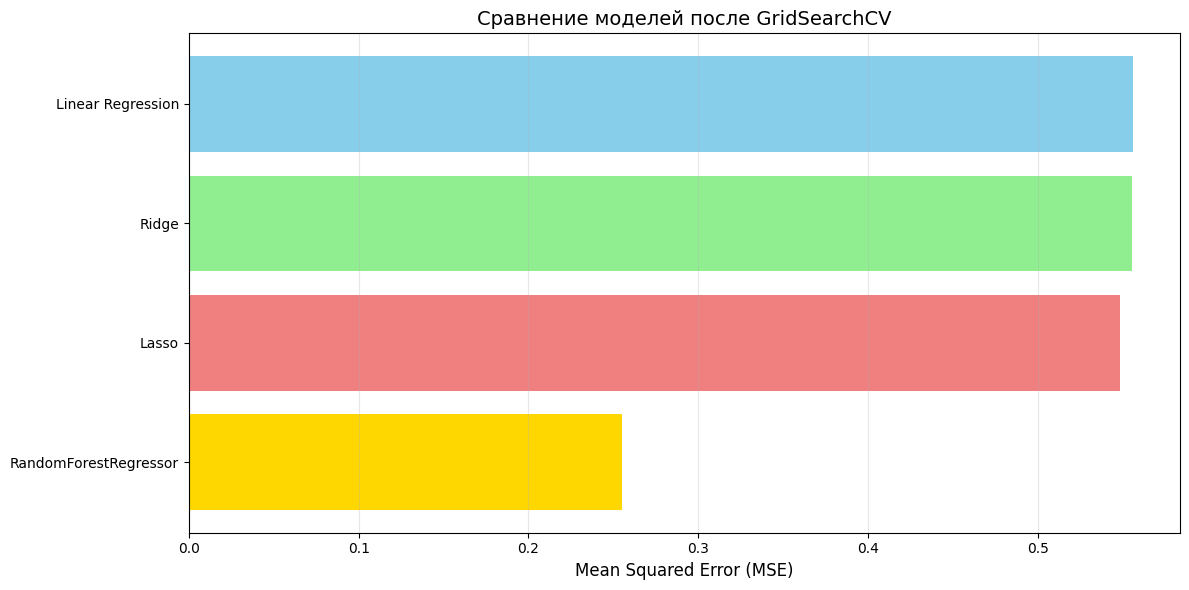


Лучшая модель: RandomForestRegressor
MSE: 0.2552


In [14]:

print("ИТОГОВОЕ СРАВНЕНИЕ МОДЕЛЕЙ ПОСЛЕ GRIDSEARCHCV")

final_results = {}

for name, model in best_models.items():
    y_pred = model.predict(x_test_scaled)
    mse = mean_squared_error(y_test, y_pred)
    final_results[name] = mse
    print(f"{name:30s} -> MSE: {round(mse, 4)}")

plt.figure(figsize=(12, 6))
colors = ['skyblue', 'lightgreen', 'lightcoral', 'gold']

plt.barh(
    list(final_results.keys()),
    list(final_results.values()),
    color=colors
)

plt.xlabel('Mean Squared Error (MSE)', fontsize=12)
plt.title('Сравнение моделей после GridSearchCV', fontsize=14)
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

best_model_name = min(final_results, key=final_results.get)

print(f"\nЛучшая модель: {best_model_name}")
print(f"MSE: {round(final_results[best_model_name], 4)}")


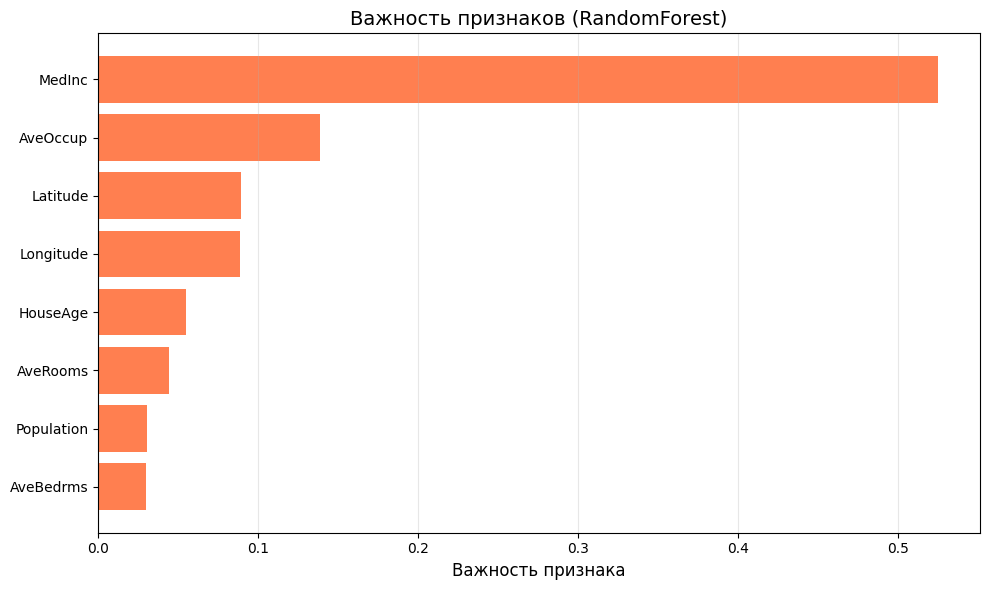


Топ-5 наиболее важных признаков:
1. MedInc: 0.5249
2. AveOccup: 0.1384
3. Latitude: 0.0889
4. Longitude: 0.0886
5. HouseAge: 0.0546


In [15]:

rf_model = best_models['RandomForestRegressor']

importances = rf_model.feature_importances_
feature_names = x.columns

feature_importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values('importance', ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance_df['feature'],
    feature_importance_df['importance'],
    color='coral'
)

plt.xlabel('Важность признака', fontsize=12)
plt.title('Важность признаков (RandomForest)', fontsize=14)
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

print("\nТоп-5 наиболее важных признаков:")

for i, row in enumerate(feature_importance_df.head(5).itertuples(), 1):
    print(f"{i}. {row.feature}: {row.importance:.4f}")


### Итоговые выводы

**1. Сравнение моделей**

RandomForestRegressor показал наилучший результат по метрике MSE. Линейные модели продемонстрировали более высокую ошибку. Подбор гиперпараметров позволил улучшить результаты Ridge и Lasso.

**2. Важность признаков**

Наиболее важным признаком оказался MedInc (медианный доход). Также заметное влияние имеют AveOccup, Latitude и Longitude. Это подтверждает значимость дохода и географического положения при прогнозировании стоимости жилья.

**3. Рекомендации**

Для данной задачи лучше всего подходит RandomForestRegressor, поскольку он способен учитывать нелинейные зависимости между признаками.

**4. Сложность моделей**

Линейные модели имеют сложность порядка O(n·d) по времени. RandomForest имеет более высокую вычислительную сложность, поскольку использует несколько деревьев решений.

**Итог:** в ходе работы были обучены и сравнены четыре модели регрессии. Наилучшее качество прогнозирования показала модель RandomForestRegressor.